## New York Times Connections Analysis

### Introduction

The New York Times is often known for its Crossword puzzle, but has expanded its offerings to include a game called Connections. This game has one free puzzle a day where users attempt to connect 4 categories of 4 words each from a total of 16 initial words. Categories are also color coded as yellow, green, blue, or purple in increasing difficulty. A reverse rainbow, the previous colors in reverse, means that the categories were solved in hardest to easiest order.


Difficulty can be subjective since categories lack inherent quantitative difficulties. We would like to discover what patterns exist within the categories by color. This may also provide insight as to whether or not categories are truly color coded based on relative difficulty.


Past Connections results are up to date as of 12/15/25 and were obtained from https://www.kaggle.com/datasets/eric27n/the-new-york-times-connections. Beware potential spoilers if you do archived puzzles.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

# from sklearn.model_selection import train_test_split
from sklearn.model_selection import GroupShuffleSplit

import nltk
nltk.download('stopwords', quiet=True)
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"

rng = np.random.default_rng(seed=42)

### Exploratory Data Analysis (EDA)

We want to collect all the group names observed for each color and clean up these lists for analysis.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/Megabuster/NYTConnections/refs/heads/main/Connections_Data.csv'
connections_df = pd.read_csv(DATA_URL)
connections_df.head()

,Game ID,Puzzle Date,Word,Group Name,Group Level,Starting Row,Starting Column
0,1,2023-06-12,SNOW,WET WEATHER,0,1,1
1,1,2023-06-12,LEVEL,PALINDROMES,3,1,2
2,1,2023-06-12,SHIFT,KEYBOARD KEYS,2,1,3
3,1,2023-06-12,KAYAK,PALINDROMES,3,1,4
4,1,2023-06-12,HEAT,NBA TEAMS,1,2,1


The dataset contains:


*  Game ID: Unique puzzle number from day to day.
*  Puzzle Date: Date the puzzle was published. This should coincide with the IDs.
*  Word: Word + Game ID or Puzzle Date should be a unique combination for each record. This would be 1 of the 16 words to connect for that day.
*  Group Name: This is typically known as the Category. There should be 4 records per day with a Group Name.
*  Group Level: This is a range from 0-3 pertaining to the relative difficulty for that day. Each day will only have 1 of each difficulty for color associations as follows:
    *  $\color{yellow}{\text{Yellow: 0}}$
    *  $\color{green}{\text{Green: 1}}$
    *  $\color{blue}{\text{Blue: 2}}$
    *  $\color{purple}{\text{Purple: 3}}$
* Starting Row/Column: These two columns combine to create a coordinate on the 4x4 grid that the game is played on. This does not inherently affect the categories, but is often not used arbitrarily. Certain word combinations are sometimes placed in an order to trick players or send messages for fun.




In [3]:
connections_df.info()
connections_df[connections_df.isna().any(axis=1)]

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Game ID          14640 non-null  int64 
 1   Puzzle Date      14640 non-null  object
 2   Word             14638 non-null  object
 3   Group Name       14640 non-null  object
 4   Group Level      14640 non-null  int64 
 5   Starting Row     14640 non-null  int64 
 6   Starting Column  14640 non-null  int64 
dtypes: int64(4), object(3)
memory usage: 800.8+ KB


,Game ID,Puzzle Date,Word,Group Name,Group Level,Starting Row,Starting Column
930,59,2023-08-09,NaN,UNSPECIFIED QUANTITIES,0,1,3
978,62,2023-08-12,NaN,PERIODIC TABLE SYMBOLS,3,1,3


A quick lookup tells us that the missing words are SOME and NA.

In [4]:
connections_df.loc[930, 'Word'] = 'SOME'
connections_df.iloc[930]
connections_df.loc[978, 'Word'] = 'NA'
connections_df.iloc[978]

,930
Game ID,59
Puzzle Date,2023-08-09
Word,SOME
Group Name,UNSPECIFIED QUANTITIES
Group Level,0
Starting Row,1
Starting Column,3


,978
Game ID,62
Puzzle Date,2023-08-12
Word,NA
Group Name,PERIODIC TABLE SYMBOLS
Group Level,3
Starting Row,1
Starting Column,3


With the missing data accounted for, we can check for recurring words.

Word
BALL        25
RING        20
WING        19
HEART       17
JACK        16
            ..
DRIP         1
GUSH         1
PIGLET       1
NAPOLEON     1
DUCKLING     1
Name: count, Length: 6886, dtype: int64


<Axes: xlabel='count', ylabel='Count'>

Text(0.5, 0, 'Word Counts')

Text(0, 0.5, 'Frequency')

Text(0.5, 1.0, 'Most words have shown up in fewer than 5 puzzles')

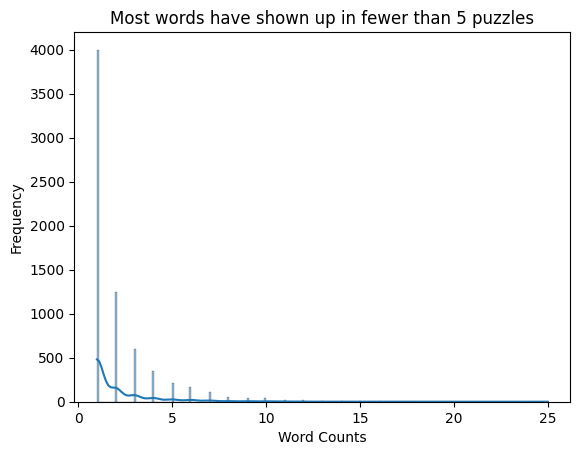

,count
Word,
BALL,25
RING,20
WING,19
HEART,17
JACK,16
BAR,16
SPLIT,16
LOVE,16
STICK,16


In [5]:
word_counts = connections_df['Word'].value_counts()
print(word_counts)

plt.close()
sns.histplot(word_counts, kde=True)
plt.xlabel('Word Counts')
plt.ylabel('Frequency')
plt.title('Most words have shown up in fewer than 5 puzzles')
plt.show()

word_counts.head(25)

Around 4000 words have occurred exactly once. Multiple words have been reused with ball being the most common. This doesn't necessarily mean that puzzles or categories repeat. Words can be connected in different ways or even be homonyms.

In [13]:
top_25_recurring = word_counts.head(25).reset_index()['Word']
recurring_groups = connections_df[connections_df['Word'].isin(top_25_recurring)]['Group Name'].value_counts().reset_index()
recurring_groups[recurring_groups['count'] > 1].head(10)


,Group Name,count
0,STEER,6
1,THINGS A DOG CAN FETCH,4
2,"FRIED APPETIZER, INFORMALLY",3
3,SLANG FOR ZERO,3
4,MALE ANIMALS,3
5,PILOT,2
6,SLANG FOR TOILET,2
7,DECLINE,2
8,"COOL, IN ’80S SLANG",2
9,MOVE QUICKLY,2


In [7]:
yellow_df = connections_df[connections_df['Group Level'] == 0]
green_df = connections_df[connections_df['Group Level'] == 1]
blue_df = connections_df[connections_df['Group Level'] == 2]
purple_df = connections_df[connections_df['Group Level'] == 3]
yellow_groups = yellow_df['Group Name'].value_counts().reset_index()
green_groups = green_df['Group Name'].value_counts().reset_index()
blue_groups = blue_df['Group Name'].value_counts().reset_index()
purple_groups = purple_df['Group Name'].value_counts().reset_index()
yellow_groups
green_groups
blue_groups
purple_groups

,Group Name,count
0,CAPTIVATE,12
1,HOMOPHONES,12
2,MUSIC GENRES,12
3,STATES OF MATTER,12
4,TINT,8
...,...,...
863,THROW OUT,4
864,TACO TOPPINGS,4
865,LAB EQUIPMENT,4
866,REFINED SENSIBILITY,4


,Group Name,count
0,MILD OATHS,12
1,ANAGRAMS,12
2,MUSICAL INSTRUMENTS,8
3,FISH,8
4,MOVE QUICKLY,8
...,...,...
874,ADJECTIVES FOR A BASEMENT,4
875,TERRA FIRMA,4
876,METRIC PREFIXES,4
877,NEXUS,4


,Group Name,count
0,GLOBAL CURRENCIES,12
1,YOGA POSES,12
2,MAGAZINES,12
3,"DOG BREEDS, INFORMALLY",12
4,BIRDS,12
...,...,...
869,TRANSACTION RECORD,4
870,WEB BROWSER MENUS,4
871,JOAQUIN PHOENIX MOVIES,4
872,UNITS OF LENGTH,4


,Group Name,count
0,HOMOPHONES,16
1,___ CAT,8
2,SPANISH WORDS,8
3,___STONE,8
4,THINGS THAT ARE PURPLE,8
...,...,...
880,___ TALK,4
881,STARTING WITH HERPETOFAUNA,4
882,EL ___,4
883,EUROPEAN CAPITALS MINUS SECOND-TO-LAST LETTER,4


From simple groupings we can see that each color has some recurring groups. However, `Yellow` and `Purple` both have had more than 10 `Homophones` groups each. This is notable because they are the supposed highest and lowest difficulties which implies that they should share the least overlap of any two categories.

Assuming that there are trends in how works and categories line up with category colors, we should be able to predict which words are likely to be which color.

In [8]:
connections_df.head()

,Game ID,Puzzle Date,Word,Group Name,Group Level,Starting Row,Starting Column
0,1,2023-06-12,SNOW,WET WEATHER,0,1,1
1,1,2023-06-12,LEVEL,PALINDROMES,3,1,2
2,1,2023-06-12,SHIFT,KEYBOARD KEYS,2,1,3
3,1,2023-06-12,KAYAK,PALINDROMES,3,1,4
4,1,2023-06-12,HEAT,NBA TEAMS,1,2,1


### Building a Classification Pipeline

In order to predict the categories and colors for the words of the day, we need to establish our training set. Since our words are correlated with the other 15 words from that same day, we will introduce data leakage if we split the dataset indiscriminantly. Instead, we will make sure to keep all the words for each game together.

In a vacuum, this would suffice. However, games evolve over time in order to keep long time players on their toes. Potential traps are more likely to appear in later games based on expectations from existing players. In order to help check for overfitting, we will have two layers of validation data: the general randomized split and the newest batch of puzzles. The model will only be tuned according to results of the randomized puzzles first.

In [9]:
# Split latest history first to ensure the model doesn't already know new patterns
# Take roughly 1 month to maximize training data
connections_df['Puzzle Date'] = pd.to_datetime(connections_df['Puzzle Date'])
final_holdout_cutoff = connections_df['Puzzle Date'].max() - pd.Timedelta(days=30)

connections_hist = connections_df[connections_df['Puzzle Date'] < final_holdout_cutoff].reset_index(drop=True)
connections_final = connections_df[connections_df['Puzzle Date'] >= final_holdout_cutoff].reset_index(drop=True)

# Splitting X (features) and y (target) into 80% train and 20% test
X_hist = connections_hist.drop(columns=['Group Level'])
y_hist = connections_hist['Group Level']
groups_hist = connections_hist['Puzzle Date']

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
train_idx, tuning_idx = next(gss.split(X_hist, y_hist, groups_hist))

# Final Split Datasets
train_set = connections_hist.iloc[train_idx].copy()
tuning_test_set = connections_hist.iloc[tuning_idx]
final_test_set = connections_final

# Diagnostic check to verify zero leakage
print(f"Training Set: {train_set['Puzzle Date'].nunique()} games ({len(train_set)} rows)")
print(f"Testing Set: {tuning_test_set['Puzzle Date'].nunique()} games ({len(tuning_test_set)} rows)")
print(f"Final Holdout Set: {final_test_set['Puzzle Date'].nunique()} games ({len(final_test_set)} rows)")


Training Set: 707 games (11312 rows)
Testing Set: 177 games (2832 rows)
Final Holdout Set: 31 games (496 rows)


One way to divide the sets could be a 60-20-20 train-test-final test split, but this leaves a lot of data usable for training. Keeping just one month of tests for the final validation maintains a clear amount of tests (one month) while providing more data for training since we have under 1000 games available.

With our training set ready, we can dig deeper for any recognizable patterns and see if we need will need to perform feature engineering.

### Identifying Category Patterns

Earlier we saw that words and groups can reappear in future puzzles, even in different group levels. This means words are not mutually exclusive across games. The provided dataset also gives us a peculiar data point: word coordinates. Puzzles do not have their answers in order because that defeats the purpose of the puzzle most of the time. The starting coordinates are likely chosen intentionally. We can see if there is a pattern of where words typically appear.


,Game ID,Puzzle Date,Word,Group Name,Group Level,Starting Row,Starting Column,Starting Coords
0,1,2023-06-12,SNOW,WET WEATHER,0,1,1,"(1, 1)"
1,1,2023-06-12,LEVEL,PALINDROMES,3,1,2,"(1, 2)"
2,1,2023-06-12,SHIFT,KEYBOARD KEYS,2,1,3,"(1, 3)"
3,1,2023-06-12,KAYAK,PALINDROMES,3,1,4,"(1, 4)"
4,1,2023-06-12,HEAT,NBA TEAMS,1,2,1,"(2, 1)"


,Starting Coords,Group Level,count
0,"(1, 1)",0,143
1,"(1, 1)",1,164
2,"(1, 1)",2,208
3,"(1, 1)",3,192
4,"(1, 2)",0,138
5,"(1, 2)",1,181
6,"(1, 2)",2,159
7,"(1, 2)",3,229


<Figure size 800x500 with 0 Axes>

<Axes: xlabel='X', ylabel='Y'>

Text(0.5, 49.444444444444436, '')

Text(94.44444444444444, 0.5, '')

Text(0.5, 1.0, 'Category Difficulty Appears To Gradually Decrease From Top Left To Bottom Right')

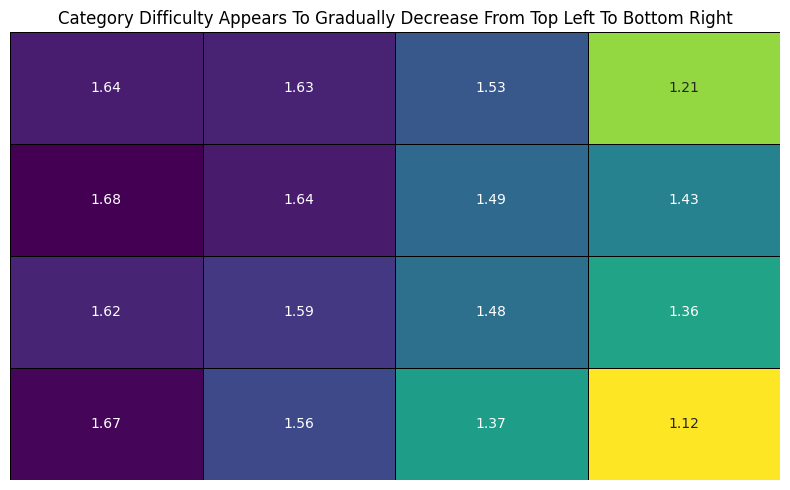

In [10]:
if 'Starting Coords' not in train_set.columns:
  train_set['Starting Coords'] = list(zip(train_set['Starting Row'], train_set['Starting Column']))
train_set.head()

level_counts = train_set.groupby(['Starting Coords', 'Group Level']).size().reset_index(name='count')
level_counts.head(8)

# From counts collect avg level = (0a + b + 2c + 3d)/total levels
# avg_level = level_counts.groupby('Starting Coords').sum()
total_games = int(len(train_set) / 16)
level_rate = level_counts['Group Level'] * level_counts['count'] / total_games
level_counts['Level Rate'] = level_rate
avg_level = level_counts.groupby('Starting Coords')['Level Rate'].sum().reset_index()
avg_level[['X', 'Y']] = pd.DataFrame(avg_level['Starting Coords'].tolist(), index=avg_level.index)
avg_level_heatmap = avg_level.pivot(index='Y', columns='X', values='Level Rate')

# Building the heatmap to look like a Connections board
plt.close()
plt.figure(figsize=(8, 5))
sns.heatmap(avg_level_heatmap,
            cmap='viridis_r',
            annot=True,
            fmt='.2f',
            cbar=False,
            linewidths=0.5,
            linecolor='black',
            xticklabels=False,
            yticklabels=False
            )
plt.xlabel('')
plt.ylabel('')
plt.title('Category Difficulty Appears To Gradually Decrease From Top Left To Bottom Right')

plt.tight_layout()
plt.show()


The bottom right square has the lowest average of all at 1.12. The leftmost column has the highest average levels with a range of 1.62-1.67. This creates a downward trend from the upper left to lower right boxes. A trend like this is unusual because it is often preferable to keep words in the same categories apart to make it harder to find patterns.

We can attempt a Monte Carlo simulation test to see if our results seem to fall within expectations. We will run 10000 simulations and compare these results to our 1.12-1.68 range.

In [11]:
base_board = [0] * 4 + [1] * 4 + [2] * 4 + [3] * 4
simulated_mins = []
simulated_maxs = []

for _ in range(10000):
  sim_data = np.array([rng.permutation(base_board) for _ in range(total_games)])
  cell_means = sim_data.mean(axis=0)
  simulated_mins.append(cell_means.min())
  simulated_maxs.append(cell_means.max())

p_min = np.mean(np.array(simulated_mins) <= 1.12)
p_max = np.mean(np.array(simulated_maxs) >= 1.68)

print(f'p-value for min: {p_min}')
print(f'p-value for max: {p_max}')

p-value for min: 0.0
p-value for max: 0.0002


Our p-values for this test are well below the alpha=0.05 significance threshold, so we will reject the null hypothesis that there is no pattern in the positions of the words. A p-value of p < 0.0001 for "min" indicates that none of the simulations had an average as extreme as the 1.12 observed one, while very few surpassed the "max" of 1.68.

#### Feature Engineering for Starting Coordinates Patterns

We can use what we learned about the word locations as features for our classifier. The five new features are `Level Rate`, which represents the average difficulty for that starting square, and four for the probabilities of each color on that square.

In [12]:
train_set.head()
coord_rate_map = avg_level.set_index('Starting Coords')[
    'Level Rate'
].to_dict()

pos_counts = level_counts.pivot(
    index='Starting Coords', columns='Group Level', values='count'
).fillna(0)

spatial_prob_map = pos_counts.div(pos_counts.sum(axis=1), axis=0).to_dict(
    orient='index'
)
train_set_eng = train_set.copy()
train_set_eng['Level Rate'] = train_set_eng['Starting Coords'].map(coord_rate_map)
train_set_eng['Spatial Yellow Prob'] = train_set_eng['Starting Coords'].apply(
    lambda x: spatial_prob_map.get(x, {}).get(0, 0.25)
)
train_set_eng['Spatial Green Prob'] = train_set_eng['Starting Coords'].apply(
    lambda x: spatial_prob_map.get(x, {}).get(1, 0.25)
)
train_set_eng['Spatial Blue Prob'] = train_set_eng['Starting Coords'].apply(
    lambda x: spatial_prob_map.get(x, {}).get(2, 0.25)
)
train_set_eng['Spatial Purple Prob'] = train_set_eng['Starting Coords'].apply(
    lambda x: spatial_prob_map.get(x, {}).get(3, 0.25)
)
train_set_eng.head()

,Game ID,Puzzle Date,Word,Group Name,Group Level,Starting Row,Starting Column,Starting Coords
0,1,2023-06-12,SNOW,WET WEATHER,0,1,1,"(1, 1)"
1,1,2023-06-12,LEVEL,PALINDROMES,3,1,2,"(1, 2)"
2,1,2023-06-12,SHIFT,KEYBOARD KEYS,2,1,3,"(1, 3)"
3,1,2023-06-12,KAYAK,PALINDROMES,3,1,4,"(1, 4)"
4,1,2023-06-12,HEAT,NBA TEAMS,1,2,1,"(2, 1)"


,Game ID,Puzzle Date,Word,Group Name,Group Level,Starting Row,Starting Column,Starting Coords,Level Rate,Spatial Yellow Prob,Spatial Green Prob,Spatial Blue Prob,Spatial Purple Prob
0,1,2023-06-12,SNOW,WET WEATHER,0,1,1,"(1, 1)",1.635078,0.202263,0.231966,0.294201,0.271570
1,1,2023-06-12,LEVEL,PALINDROMES,3,1,2,"(1, 2)",1.677511,0.195191,0.256011,0.224894,0.323904
2,1,2023-06-12,SHIFT,KEYBOARD KEYS,2,1,3,"(1, 3)",1.622348,0.223479,0.212164,0.282885,0.281471
3,1,2023-06-12,KAYAK,PALINDROMES,3,1,4,"(1, 4)",1.670438,0.207921,0.240453,0.224894,0.326733
4,1,2023-06-12,HEAT,NBA TEAMS,1,2,1,"(2, 1)",1.625177,0.213579,0.253182,0.227723,0.305516
